# Sprint 2 — Testes de hipótese da média e da proporção (tempo de processamento do Pix)

Variável `Tempo_processamento_seg` (segundos). Planilha 1 = população (antes); Planilha 2 = amostra (depois da etapa antifraude).
Os textos de análise, as fórmulas e as conclusões estão no relatório `Relatorio_Sprint2.docx`.

## 1. Importar as bibliotecas

In [1]:
# pandas: lê as planilhas do Excel e monta as tabelas de resultados.
import pandas as pd
# numpy: gera a sequência de valores de z usada para desenhar a curva normal (np.linspace).
import numpy as np
# math: fornece a raiz quadrada (math.sqrt) usada nos erros-padrão.
import math
# seaborn: mantém o mesmo padrão de bibliotecas gráficas da Sprint 1.
import seaborn as sns
# matplotlib.pyplot: desenha as curvas, pinta as regiões e exibe os gráficos.
import matplotlib.pyplot as plt
# norm (distribuição normal): cdf = probabilidade acumulada, ppf = valor crítico (inverso da cdf), pdf = altura da curva.
from scipy.stats import norm

## 2. Definir as variáveis `arquivo_antes`, `arquivo_depois` e `coluna`

In [2]:
# Caminho da Planilha 1 (300 observações antes da intervenção), tratada como população de referência.
arquivo_antes = "../Refs/Planilha 1 - TEMPO PAGAMENTO PIX.xlsx"
# Caminho da Planilha 2 (100 observações depois da intervenção), tratada como amostra.
arquivo_depois = "../Refs/Planilha 2 -TEMPO PAGAMENTO PIX-2.xlsx"
# Nome da coluna com o tempo de processamento, em segundos.
coluna = "Tempo_processamento_seg"

## 3. Leitura dos arquivos de dados

In [3]:
# Lê a Planilha 1 e guarda os dados de antes da intervenção em df_antes.
df_antes=pd.read_excel(arquivo_antes)
# Lê a Planilha 2 e guarda os dados de depois da intervenção em df_depois.
df_depois=pd.read_excel(arquivo_depois)
# Confere o tamanho de cada planilha (esperado: 300 e 100 observações).
print(f'Planilha 1: {len(df_antes)} observações | Planilha 2: {len(df_depois)} observações')

Planilha 1: 300 observações | Planilha 2: 100 observações


## Introdução — correção do intervalo usado na Sprint 1

In [4]:
# A Sprint 1 contou a Planilha 2 no intervalo [0, 6] s (Questão 7.4), diferente do [2, 3] s da Questão 5.
quantidade_0_6 = sum(i>=0 and i<=6 for i in df_depois[coluna])
# Para comparar p e p-chapéu, os dois precisam usar o mesmo intervalo: [2, 3] s, o da Questão 5.
quantidade_2_3 = sum(i>=2 and i<=3 for i in df_depois[coluna])
# Mostra a contagem antiga (só referência) e a contagem corrigida, usada nesta Sprint.
print(f'Intervalo [0, 6] s (Sprint 1, Questão 7.4): {quantidade_0_6} de {len(df_depois)}')
# Mostra a contagem no intervalo corrigido.
print(f'Intervalo [2, 3] s (corrigido, igual à Questão 5): {quantidade_2_3} de {len(df_depois)}')

Intervalo [0, 6] s (Sprint 1, Questão 7.4): 85 de 100
Intervalo [2, 3] s (corrigido, igual à Questão 5): 0 de 100


## Questão 1 — Parâmetros da população (antes) e da amostra (depois)

In [5]:
# Média da população (Planilha 1), arredondada em 2 casas como na Sprint 1.
media_pop = round(df_antes[coluna].mean(), 2)
# Desvio-padrão da Planilha 1 (sigma), arredondado em 2 casas.
dpad_pop = round(df_antes[coluna].std(), 2)
# p = P(2 <= X <= 3) pela normal com média e desvio da Planilha 1 (mesmo comando da Questão 5 da Sprint 1).
p_pop = norm.cdf(3,loc=media_pop,scale=dpad_pop).round(4)-norm.cdf(2,loc=media_pop,scale=dpad_pop).round(4)
# Média da amostra (Planilha 2), arredondada em 2 casas.
media_amostra = round(df_depois[coluna].mean(), 2)
# Desvio-padrão da amostra (Planilha 2), só para comparação descritiva.
dpad_amostra = round(df_depois[coluna].std(), 2)
# n = tamanho da amostra.
n = len(df_depois[coluna])
# Conta quantas transações da Planilha 2 ficaram entre 2 e 3 segundos.
quantidade_faixa_ideal=sum(i>=2 and i<=3 for i in df_depois[coluna].sort_values())
# p-chapéu = proporção amostral = quantidade no intervalo / n.
p_chapeu = quantidade_faixa_ideal/n
# Mostra os parâmetros da população.
print(f'População (Planilha 1): média = {media_pop:.2f} s | desvio-padrão = {dpad_pop:.2f} s | p = {p_pop:.4f}')
# Mostra os valores da amostra.
print(f'Amostra (Planilha 2): n = {n} | média = {media_amostra:.2f} s | desvio-padrão = {dpad_amostra:.2f} s | p-chapéu = {quantidade_faixa_ideal}/{n} = {p_chapeu:.4f}')

População (Planilha 1): média = 2.51 s | desvio-padrão = 0.40 s | p = 0.7885
Amostra (Planilha 2): n = 100 | média = 5.10 s | desvio-padrão = 0.81 s | p-chapéu = 0/100 = 0.0000


In [6]:
# Tabela comparativa: cada linha é uma medida; as colunas trazem antes, depois e a diferença.
tabela_q1 = pd.DataFrame(
    {
        "Medida": ["Média do tempo", "Proporção entre 2 e 3 segundos"],
        "Unidade": ["segundos", "% das transações"],
        "Antes — população (Planilha 1)": [f"{media_pop:.2f}", f"{p_pop:.2%}"],
        "Depois — amostra (Planilha 2)": [f"{media_amostra:.2f}", f"{p_chapeu:.2%}"],
        "Diferença (depois - antes)": [f"{media_amostra - media_pop:+.2f} s", f"{(p_chapeu - p_pop)*100:+.2f} p.p."],
    }
)
# Exibe a tabela comparativa.
tabela_q1

,Medida,Unidade,Antes — população (Planilha 1),Depois — amostra (Planilha 2),Diferença (depois - antes)
0,Média do tempo,segundos,2.51,5.10,+2.59 s
1,Proporção entre 2 e 3 segundos,% das transações,78.85%,0.00%,-78.85 p.p.


## Questão 2a — Hipóteses do teste da média

In [7]:
# mu_0 = valor de referência da hipótese nula: a média da Planilha 1.
mu_0 = media_pop
# H0 (hipótese nula): a média continua igual à de antes da intervenção.
print(f'H0: mu = {mu_0:.2f} segundos')
# H1 (hipótese alternativa): a média aumentou -> teste unilateral à direita.
print(f'H1: mu > {mu_0:.2f} segundos (unilateral à direita)')

H0: mu = 2.51 segundos
H1: mu > 2.51 segundos (unilateral à direita)


## Questão 2b — Teste da média: z calculado, valores críticos e regiões (1% e 5%)

In [8]:
# Fórmula do erro-padrão da média: sigma / raiz(n), com sigma = desvio-padrão da Planilha 1.
erro_padrao_media = dpad_pop/math.sqrt(n)
# Fórmula da estatística do teste: z = (média da amostra - mu_0) / erro-padrão.
z_media = round((media_amostra-mu_0)/erro_padrao_media,2)
# Mostra o erro-padrão.
print(f'Erro-padrão = {dpad_pop} / raiz({n}) = {erro_padrao_media:.2f} segundo')
# Mostra o z calculado.
print(f'z calculado = ({media_amostra:.2f} - {mu_0:.2f}) / {erro_padrao_media:.2f} = {z_media}')

Erro-padrão = 0.4 / raiz(100) = 0.04 segundo
z calculado = (5.10 - 2.51) / 0.04 = 64.75


### Nível de significância de 1%

In [9]:
# alfa = nível de significância = probabilidade máxima aceita de rejeitar H0 sendo ela verdadeira.
alfa = 0.01
# Teste unilateral à direita: o z crítico deixa alfa de área na cauda direita, então usa-se ppf(1 - alfa).
z_critico_media_1 = norm.ppf(1-alfa).round(3)
# Mostra o valor crítico.
print(f'alfa = {alfa:.0%} | z crítico = {z_critico_media_1}')
# Região de não rejeição de H0: valores de z até o z crítico.
print(f'Região de não rejeição de H0: z <= {z_critico_media_1}')
# Região de rejeição de H0: valores de z acima do z crítico.
print(f'Região de rejeição de H0: z > {z_critico_media_1}')
# Regra de decisão: se o z calculado cai na região de rejeição, rejeita-se H0.
if z_media > z_critico_media_1:
    # z calculado maior que o z crítico.
    print(f'Decisão: z = {z_media} > {z_critico_media_1} -> rejeita-se H0 ao nível de {alfa:.0%}.')
else:
    # z calculado menor ou igual ao z crítico.
    print(f'Decisão: z = {z_media} <= {z_critico_media_1} -> não se rejeita H0 ao nível de {alfa:.0%}.')

alfa = 1% | z crítico = 2.326
Região de não rejeição de H0: z <= 2.326
Região de rejeição de H0: z > 2.326
Decisão: z = 64.75 > 2.326 -> rejeita-se H0 ao nível de 1%.


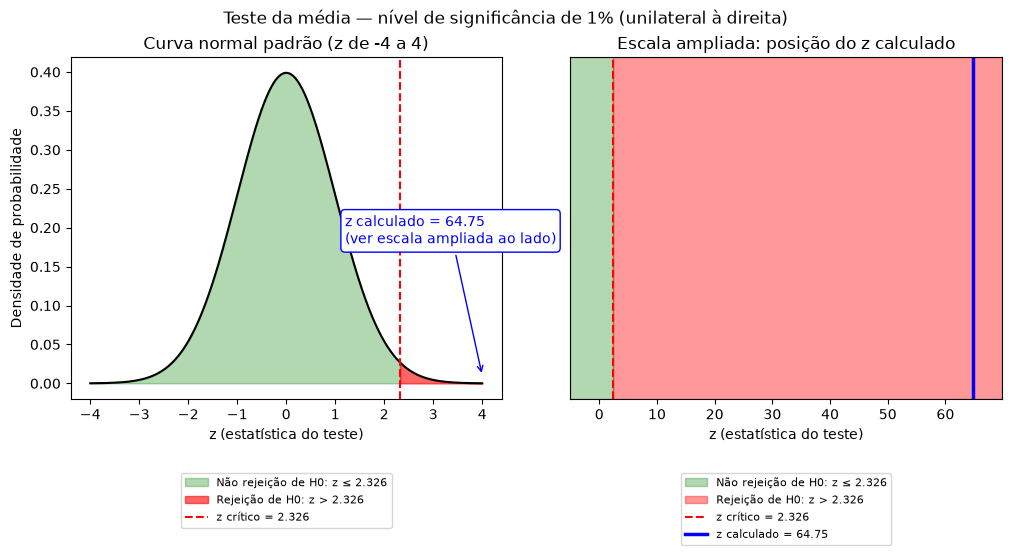

In [10]:
# Figura com dois painéis lado a lado: à esquerda a curva normal padrão (z de -4 a 4); à direita uma escala ampliada que contém o z calculado.
fig, (ax_curva, ax_escala) = plt.subplots(1, 2, figsize=(10, 5.4), layout="constrained")
# Valores de z de -4 a 4, faixa onde está praticamente toda a área da normal padrão.
x = np.linspace(-4, 4, 1000)
# Painel da esquerda: curva normal padrão, a distribuição de z se H0 for verdadeira.
ax_curva.plot(x, norm.pdf(x), color="black")
# Pinta de verde a área de não rejeição (z <= z crítico).
ax_curva.fill_between(x, norm.pdf(x), where=(x <= z_critico_media_1), color="green", alpha=0.3, label=f"Não rejeição de H0: z ≤ {z_critico_media_1}")
# Pinta de vermelho a área de rejeição (z > z crítico), que tem área igual a alfa.
ax_curva.fill_between(x, norm.pdf(x), where=(x >= z_critico_media_1), color="red", alpha=0.6, label=f"Rejeição de H0: z > {z_critico_media_1}")
# Linha tracejada no z crítico, a fronteira entre as duas regiões (o valor aparece na legenda).
ax_curva.axvline(z_critico_media_1, color="red", linestyle="--", label=f"z crítico = {z_critico_media_1}")
# O z calculado fica muito além de 4, então aqui é só uma seta na borda direita; a posição exata está no painel da direita.
ax_curva.annotate(f"z calculado = {z_media}\n(ver escala ampliada ao lado)", xy=(4, 0.01), xytext=(1.2, 0.18), arrowprops=dict(arrowstyle="->", color="blue"), color="blue", bbox=dict(boxstyle="round", fc="white", ec="blue"))
# Título do painel da esquerda.
ax_curva.set_title("Curva normal padrão (z de -4 a 4)")
# Rótulo do eixo x do painel da esquerda.
ax_curva.set_xlabel("z (estatística do teste)")
# Rótulo do eixo y do painel da esquerda.
ax_curva.set_ylabel("Densidade de probabilidade")
# Legenda das regiões abaixo do painel da esquerda, para não cobrir a curva.
ax_curva.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Painel da direita: o eixo vai de -5 até um pouco depois do z calculado, para que ele apareça no gráfico.
ax_escala.set_xlim(-5, z_media + 5)
# Faixa verde: região de não rejeição, de -5 até o z crítico.
ax_escala.axvspan(-5, z_critico_media_1, color="green", alpha=0.3, label=f"Não rejeição de H0: z ≤ {z_critico_media_1}")
# Faixa vermelha: região de rejeição, do z crítico até o fim da escala.
ax_escala.axvspan(z_critico_media_1, z_media + 5, color="red", alpha=0.4, label=f"Rejeição de H0: z > {z_critico_media_1}")
# Linha tracejada no z crítico (começo da região de rejeição).
ax_escala.axvline(z_critico_media_1, color="red", linestyle="--", label=f"z crítico = {z_critico_media_1}")
# Linha azul contínua no z calculado, que cai dentro da região de rejeição.
ax_escala.axvline(z_media, color="blue", linewidth=2.5, label=f"z calculado = {z_media}")
# Esconde o eixo y, que não tem significado nesta escala.
ax_escala.set_yticks([])
# Título do painel da direita.
ax_escala.set_title("Escala ampliada: posição do z calculado")
# Rótulo do eixo x do painel da direita.
ax_escala.set_xlabel("z (estatística do teste)")
# Legenda abaixo do painel da direita.
ax_escala.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Título geral da figura com o teste e o nível de significância.
fig.suptitle("Teste da média — nível de significância de 1% (unilateral à direita)")
# Exibe o gráfico.
plt.show()


### Nível de significância de 5%

In [11]:
# alfa = nível de significância = probabilidade máxima aceita de rejeitar H0 sendo ela verdadeira.
alfa = 0.05
# Teste unilateral à direita: o z crítico deixa alfa de área na cauda direita, então usa-se ppf(1 - alfa).
z_critico_media_5 = norm.ppf(1-alfa).round(3)
# Mostra o valor crítico.
print(f'alfa = {alfa:.0%} | z crítico = {z_critico_media_5}')
# Região de não rejeição de H0: valores de z até o z crítico.
print(f'Região de não rejeição de H0: z <= {z_critico_media_5}')
# Região de rejeição de H0: valores de z acima do z crítico.
print(f'Região de rejeição de H0: z > {z_critico_media_5}')
# Regra de decisão: se o z calculado cai na região de rejeição, rejeita-se H0.
if z_media > z_critico_media_5:
    # z calculado maior que o z crítico.
    print(f'Decisão: z = {z_media} > {z_critico_media_5} -> rejeita-se H0 ao nível de {alfa:.0%}.')
else:
    # z calculado menor ou igual ao z crítico.
    print(f'Decisão: z = {z_media} <= {z_critico_media_5} -> não se rejeita H0 ao nível de {alfa:.0%}.')

alfa = 5% | z crítico = 1.645
Região de não rejeição de H0: z <= 1.645
Região de rejeição de H0: z > 1.645
Decisão: z = 64.75 > 1.645 -> rejeita-se H0 ao nível de 5%.


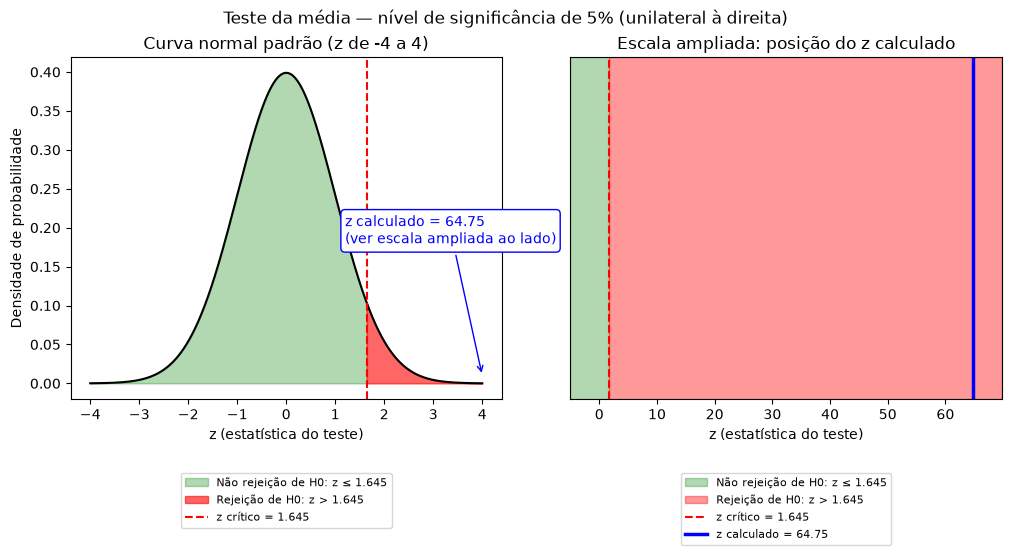

In [12]:
# Figura com dois painéis lado a lado: à esquerda a curva normal padrão (z de -4 a 4); à direita uma escala ampliada que contém o z calculado.
fig, (ax_curva, ax_escala) = plt.subplots(1, 2, figsize=(10, 5.4), layout="constrained")
# Valores de z de -4 a 4, faixa onde está praticamente toda a área da normal padrão.
x = np.linspace(-4, 4, 1000)
# Painel da esquerda: curva normal padrão, a distribuição de z se H0 for verdadeira.
ax_curva.plot(x, norm.pdf(x), color="black")
# Pinta de verde a área de não rejeição (z <= z crítico).
ax_curva.fill_between(x, norm.pdf(x), where=(x <= z_critico_media_5), color="green", alpha=0.3, label=f"Não rejeição de H0: z ≤ {z_critico_media_5}")
# Pinta de vermelho a área de rejeição (z > z crítico), que tem área igual a alfa.
ax_curva.fill_between(x, norm.pdf(x), where=(x >= z_critico_media_5), color="red", alpha=0.6, label=f"Rejeição de H0: z > {z_critico_media_5}")
# Linha tracejada no z crítico, a fronteira entre as duas regiões (o valor aparece na legenda).
ax_curva.axvline(z_critico_media_5, color="red", linestyle="--", label=f"z crítico = {z_critico_media_5}")
# O z calculado fica muito além de 4, então aqui é só uma seta na borda direita; a posição exata está no painel da direita.
ax_curva.annotate(f"z calculado = {z_media}\n(ver escala ampliada ao lado)", xy=(4, 0.01), xytext=(1.2, 0.18), arrowprops=dict(arrowstyle="->", color="blue"), color="blue", bbox=dict(boxstyle="round", fc="white", ec="blue"))
# Título do painel da esquerda.
ax_curva.set_title("Curva normal padrão (z de -4 a 4)")
# Rótulo do eixo x do painel da esquerda.
ax_curva.set_xlabel("z (estatística do teste)")
# Rótulo do eixo y do painel da esquerda.
ax_curva.set_ylabel("Densidade de probabilidade")
# Legenda das regiões abaixo do painel da esquerda, para não cobrir a curva.
ax_curva.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Painel da direita: o eixo vai de -5 até um pouco depois do z calculado, para que ele apareça no gráfico.
ax_escala.set_xlim(-5, z_media + 5)
# Faixa verde: região de não rejeição, de -5 até o z crítico.
ax_escala.axvspan(-5, z_critico_media_5, color="green", alpha=0.3, label=f"Não rejeição de H0: z ≤ {z_critico_media_5}")
# Faixa vermelha: região de rejeição, do z crítico até o fim da escala.
ax_escala.axvspan(z_critico_media_5, z_media + 5, color="red", alpha=0.4, label=f"Rejeição de H0: z > {z_critico_media_5}")
# Linha tracejada no z crítico (começo da região de rejeição).
ax_escala.axvline(z_critico_media_5, color="red", linestyle="--", label=f"z crítico = {z_critico_media_5}")
# Linha azul contínua no z calculado, que cai dentro da região de rejeição.
ax_escala.axvline(z_media, color="blue", linewidth=2.5, label=f"z calculado = {z_media}")
# Esconde o eixo y, que não tem significado nesta escala.
ax_escala.set_yticks([])
# Título do painel da direita.
ax_escala.set_title("Escala ampliada: posição do z calculado")
# Rótulo do eixo x do painel da direita.
ax_escala.set_xlabel("z (estatística do teste)")
# Legenda abaixo do painel da direita.
ax_escala.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Título geral da figura com o teste e o nível de significância.
fig.suptitle("Teste da média — nível de significância de 5% (unilateral à direita)")
# Exibe o gráfico.
plt.show()


## Questão 2c — Teste da média × análise preliminar (Questão 1)

In [13]:
# Análise preliminar (Questão 1): a média da amostra é maior que a da população?
indicio_aumento = media_amostra > mu_0
# Resultado do teste: H0 foi rejeitada a favor de H1 (mu > mu_0) nos dois níveis?
rejeita_media_1 = z_media > z_critico_media_1
# Mesmo teste para o nível de 5%.
rejeita_media_5 = z_media > z_critico_media_5
# Mostra a diferença observada na análise preliminar.
print(f'Análise preliminar: média {mu_0:.2f} s -> {media_amostra:.2f} s (diferença de {media_amostra - mu_0:+.2f} s)')
# As conclusões coincidem quando o teste confirma (ou não) o mesmo sentido do indício preliminar.
if indicio_aumento == rejeita_media_1 == rejeita_media_5:
    # Teste e análise preliminar apontam na mesma direção.
    print('As conclusões coincidem: o teste confirma, a 1% e a 5%, o aumento do tempo médio indicado na Questão 1.')
else:
    # Teste e análise preliminar apontam em direções diferentes.
    print('As conclusões não coincidem: ver discussão no relatório.')
# Sensibilidade: z recalculado com o desvio-padrão da amostra (0,81 s) no lugar do sigma da Planilha 1.
z_media_com_s = round((media_amostra-mu_0)/(dpad_amostra/math.sqrt(n)),2)
# Mostra que a decisão não depende da escolha do desvio-padrão.
print(f'Com o desvio-padrão da amostra, z = {z_media_com_s} (continua acima de {z_critico_media_1} e de {z_critico_media_5}).')

Análise preliminar: média 2.51 s -> 5.10 s (diferença de +2.59 s)
As conclusões coincidem: o teste confirma, a 1% e a 5%, o aumento do tempo médio indicado na Questão 1.
Com o desvio-padrão da amostra, z = 31.98 (continua acima de 2.326 e de 1.645).


## Questão 3a — Hipóteses do teste da proporção (intervalo [2, 3] segundos)

In [14]:
# p_0 = valor de referência da hipótese nula: a probabilidade da Planilha 1 no intervalo [2, 3] s.
p_0 = p_pop
# H0 (hipótese nula): a proporção na faixa ideal continua igual à de antes.
print(f'H0: p = {p_0:.4f}')
# H1 (hipótese alternativa): a proporção diminuiu -> teste unilateral à esquerda.
print(f'H1: p < {p_0:.4f} (unilateral à esquerda)')

H0: p = 0.7885
H1: p < 0.7885 (unilateral à esquerda)


## Questão 3b — Teste da proporção: z calculado, valores críticos e regiões (1% e 5%)

In [15]:
# Condição para aproximar a proporção pela normal: n * p0 >= 5.
condicao_1 = n*p_0
# Segunda condição: n * (1 - p0) >= 5.
condicao_2 = n*(1-p_0)
# Mostra as duas condições.
print(f'n*p0 = {condicao_1:.2f} | n*(1-p0) = {condicao_2:.2f} (ambas >= 5: aproximação normal adequada)')
# Fórmula do erro-padrão da proporção: raiz(p0 * (1 - p0) / n), usando o p0 da hipótese nula.
erro_padrao_prop = math.sqrt(p_0*(1-p_0)/n)
# Fórmula da estatística do teste: z = (p-chapéu - p0) / erro-padrão.
z_prop = round((p_chapeu-p_0)/erro_padrao_prop,2)
# Mostra o erro-padrão.
print(f'Erro-padrão = raiz({p_0:.4f} * {1-p_0:.4f} / {n}) = {erro_padrao_prop:.4f}')
# Mostra o z calculado.
print(f'z calculado = ({p_chapeu:.4f} - {p_0:.4f}) / {erro_padrao_prop:.4f} = {z_prop}')

n*p0 = 78.85 | n*(1-p0) = 21.15 (ambas >= 5: aproximação normal adequada)
Erro-padrão = raiz(0.7885 * 0.2115 / 100) = 0.0408
z calculado = (0.0000 - 0.7885) / 0.0408 = -19.31


### Nível de significância de 1%

In [16]:
# alfa = nível de significância do teste.
alfa = 0.01
# Teste unilateral à esquerda: o z crítico deixa alfa de área na cauda esquerda, então usa-se ppf(alfa) (valor negativo).
z_critico_prop_1 = norm.ppf(alfa).round(3)
# Mostra o valor crítico.
print(f'alfa = {alfa:.0%} | z crítico = {z_critico_prop_1}')
# Região de não rejeição de H0: valores de z a partir do z crítico.
print(f'Região de não rejeição de H0: z >= {z_critico_prop_1}')
# Região de rejeição de H0: valores de z abaixo do z crítico.
print(f'Região de rejeição de H0: z < {z_critico_prop_1}')
# Regra de decisão: se o z calculado cai na região de rejeição, rejeita-se H0.
if z_prop < z_critico_prop_1:
    # z calculado menor que o z crítico.
    print(f'Decisão: z = {z_prop} < {z_critico_prop_1} -> rejeita-se H0 ao nível de {alfa:.0%}.')
else:
    # z calculado maior ou igual ao z crítico.
    print(f'Decisão: z = {z_prop} >= {z_critico_prop_1} -> não se rejeita H0 ao nível de {alfa:.0%}.')

alfa = 1% | z crítico = -2.326
Região de não rejeição de H0: z >= -2.326
Região de rejeição de H0: z < -2.326
Decisão: z = -19.31 < -2.326 -> rejeita-se H0 ao nível de 1%.


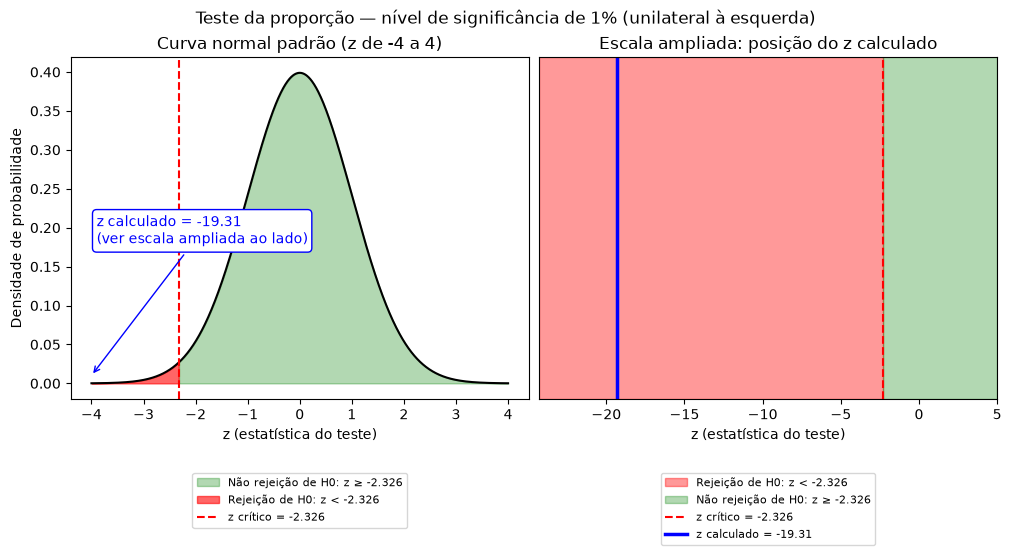

In [17]:
# Figura com dois painéis lado a lado: à esquerda a curva normal padrão (z de -4 a 4); à direita uma escala ampliada que contém o z calculado.
fig, (ax_curva, ax_escala) = plt.subplots(1, 2, figsize=(10, 5.4), layout="constrained")
# Valores de z de -4 a 4 para desenhar a curva normal padrão.
x = np.linspace(-4, 4, 1000)
# Painel da esquerda: curva normal padrão, a distribuição de z se H0 for verdadeira.
ax_curva.plot(x, norm.pdf(x), color="black")
# Pinta de verde a área de não rejeição (z >= z crítico).
ax_curva.fill_between(x, norm.pdf(x), where=(x >= z_critico_prop_1), color="green", alpha=0.3, label=f"Não rejeição de H0: z ≥ {z_critico_prop_1}")
# Pinta de vermelho a área de rejeição (z < z crítico), na cauda esquerda, com área igual a alfa.
ax_curva.fill_between(x, norm.pdf(x), where=(x <= z_critico_prop_1), color="red", alpha=0.6, label=f"Rejeição de H0: z < {z_critico_prop_1}")
# Linha tracejada no z crítico, a fronteira entre as duas regiões (o valor aparece na legenda).
ax_curva.axvline(z_critico_prop_1, color="red", linestyle="--", label=f"z crítico = {z_critico_prop_1}")
# O z calculado fica muito abaixo de -4, então aqui é só uma seta na borda esquerda; a posição exata está no painel da direita.
ax_curva.annotate(f"z calculado = {z_prop}\n(ver escala ampliada ao lado)", xy=(-4, 0.01), xytext=(-3.9, 0.18), arrowprops=dict(arrowstyle="->", color="blue"), color="blue", bbox=dict(boxstyle="round", fc="white", ec="blue"))
# Título do painel da esquerda.
ax_curva.set_title("Curva normal padrão (z de -4 a 4)")
# Rótulo do eixo x do painel da esquerda.
ax_curva.set_xlabel("z (estatística do teste)")
# Rótulo do eixo y do painel da esquerda.
ax_curva.set_ylabel("Densidade de probabilidade")
# Legenda das regiões abaixo do painel da esquerda, para não cobrir a curva.
ax_curva.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Painel da direita: o eixo vai de um pouco antes do z calculado até 5, para que ele apareça no gráfico.
ax_escala.set_xlim(z_prop - 5, 5)
# Faixa vermelha: região de rejeição, do começo da escala até o z crítico.
ax_escala.axvspan(z_prop - 5, z_critico_prop_1, color="red", alpha=0.4, label=f"Rejeição de H0: z < {z_critico_prop_1}")
# Faixa verde: região de não rejeição, do z crítico até o fim da escala.
ax_escala.axvspan(z_critico_prop_1, 5, color="green", alpha=0.3, label=f"Não rejeição de H0: z ≥ {z_critico_prop_1}")
# Linha tracejada no z crítico (fim da região de rejeição).
ax_escala.axvline(z_critico_prop_1, color="red", linestyle="--", label=f"z crítico = {z_critico_prop_1}")
# Linha azul contínua no z calculado, que cai dentro da região de rejeição.
ax_escala.axvline(z_prop, color="blue", linewidth=2.5, label=f"z calculado = {z_prop}")
# Esconde o eixo y, que não tem significado nesta escala.
ax_escala.set_yticks([])
# Título do painel da direita.
ax_escala.set_title("Escala ampliada: posição do z calculado")
# Rótulo do eixo x do painel da direita.
ax_escala.set_xlabel("z (estatística do teste)")
# Legenda abaixo do painel da direita.
ax_escala.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Título geral da figura com o teste e o nível de significância.
fig.suptitle("Teste da proporção — nível de significância de 1% (unilateral à esquerda)")
# Exibe o gráfico.
plt.show()


### Nível de significância de 5%

In [18]:
# alfa = nível de significância do teste.
alfa = 0.05
# Teste unilateral à esquerda: o z crítico deixa alfa de área na cauda esquerda, então usa-se ppf(alfa) (valor negativo).
z_critico_prop_5 = norm.ppf(alfa).round(3)
# Mostra o valor crítico.
print(f'alfa = {alfa:.0%} | z crítico = {z_critico_prop_5}')
# Região de não rejeição de H0: valores de z a partir do z crítico.
print(f'Região de não rejeição de H0: z >= {z_critico_prop_5}')
# Região de rejeição de H0: valores de z abaixo do z crítico.
print(f'Região de rejeição de H0: z < {z_critico_prop_5}')
# Regra de decisão: se o z calculado cai na região de rejeição, rejeita-se H0.
if z_prop < z_critico_prop_5:
    # z calculado menor que o z crítico.
    print(f'Decisão: z = {z_prop} < {z_critico_prop_5} -> rejeita-se H0 ao nível de {alfa:.0%}.')
else:
    # z calculado maior ou igual ao z crítico.
    print(f'Decisão: z = {z_prop} >= {z_critico_prop_5} -> não se rejeita H0 ao nível de {alfa:.0%}.')

alfa = 5% | z crítico = -1.645
Região de não rejeição de H0: z >= -1.645
Região de rejeição de H0: z < -1.645
Decisão: z = -19.31 < -1.645 -> rejeita-se H0 ao nível de 5%.


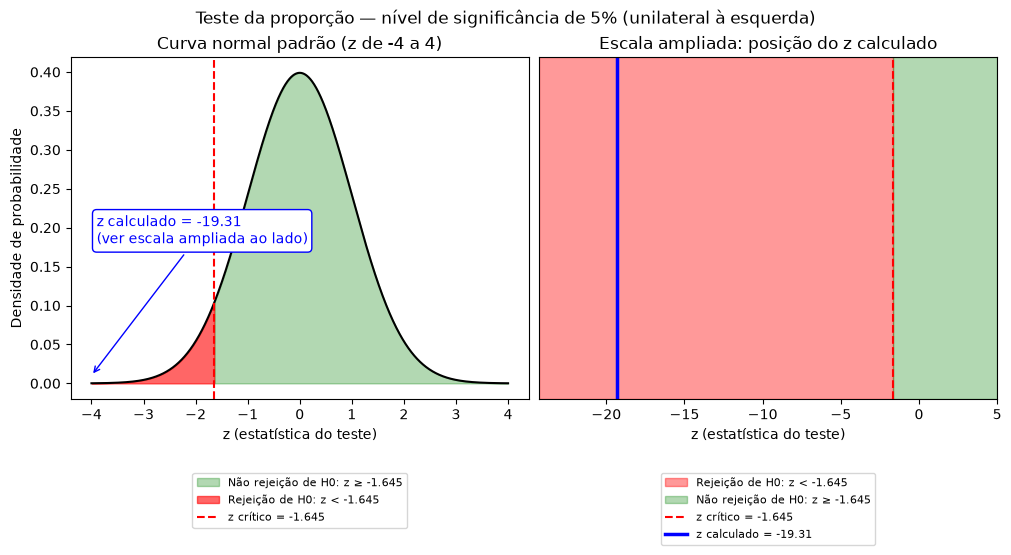

In [19]:
# Figura com dois painéis lado a lado: à esquerda a curva normal padrão (z de -4 a 4); à direita uma escala ampliada que contém o z calculado.
fig, (ax_curva, ax_escala) = plt.subplots(1, 2, figsize=(10, 5.4), layout="constrained")
# Valores de z de -4 a 4 para desenhar a curva normal padrão.
x = np.linspace(-4, 4, 1000)
# Painel da esquerda: curva normal padrão, a distribuição de z se H0 for verdadeira.
ax_curva.plot(x, norm.pdf(x), color="black")
# Pinta de verde a área de não rejeição (z >= z crítico).
ax_curva.fill_between(x, norm.pdf(x), where=(x >= z_critico_prop_5), color="green", alpha=0.3, label=f"Não rejeição de H0: z ≥ {z_critico_prop_5}")
# Pinta de vermelho a área de rejeição (z < z crítico), na cauda esquerda, com área igual a alfa.
ax_curva.fill_between(x, norm.pdf(x), where=(x <= z_critico_prop_5), color="red", alpha=0.6, label=f"Rejeição de H0: z < {z_critico_prop_5}")
# Linha tracejada no z crítico, a fronteira entre as duas regiões (o valor aparece na legenda).
ax_curva.axvline(z_critico_prop_5, color="red", linestyle="--", label=f"z crítico = {z_critico_prop_5}")
# O z calculado fica muito abaixo de -4, então aqui é só uma seta na borda esquerda; a posição exata está no painel da direita.
ax_curva.annotate(f"z calculado = {z_prop}\n(ver escala ampliada ao lado)", xy=(-4, 0.01), xytext=(-3.9, 0.18), arrowprops=dict(arrowstyle="->", color="blue"), color="blue", bbox=dict(boxstyle="round", fc="white", ec="blue"))
# Título do painel da esquerda.
ax_curva.set_title("Curva normal padrão (z de -4 a 4)")
# Rótulo do eixo x do painel da esquerda.
ax_curva.set_xlabel("z (estatística do teste)")
# Rótulo do eixo y do painel da esquerda.
ax_curva.set_ylabel("Densidade de probabilidade")
# Legenda das regiões abaixo do painel da esquerda, para não cobrir a curva.
ax_curva.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Painel da direita: o eixo vai de um pouco antes do z calculado até 5, para que ele apareça no gráfico.
ax_escala.set_xlim(z_prop - 5, 5)
# Faixa vermelha: região de rejeição, do começo da escala até o z crítico.
ax_escala.axvspan(z_prop - 5, z_critico_prop_5, color="red", alpha=0.4, label=f"Rejeição de H0: z < {z_critico_prop_5}")
# Faixa verde: região de não rejeição, do z crítico até o fim da escala.
ax_escala.axvspan(z_critico_prop_5, 5, color="green", alpha=0.3, label=f"Não rejeição de H0: z ≥ {z_critico_prop_5}")
# Linha tracejada no z crítico (fim da região de rejeição).
ax_escala.axvline(z_critico_prop_5, color="red", linestyle="--", label=f"z crítico = {z_critico_prop_5}")
# Linha azul contínua no z calculado, que cai dentro da região de rejeição.
ax_escala.axvline(z_prop, color="blue", linewidth=2.5, label=f"z calculado = {z_prop}")
# Esconde o eixo y, que não tem significado nesta escala.
ax_escala.set_yticks([])
# Título do painel da direita.
ax_escala.set_title("Escala ampliada: posição do z calculado")
# Rótulo do eixo x do painel da direita.
ax_escala.set_xlabel("z (estatística do teste)")
# Legenda abaixo do painel da direita.
ax_escala.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
# Título geral da figura com o teste e o nível de significância.
fig.suptitle("Teste da proporção — nível de significância de 5% (unilateral à esquerda)")
# Exibe o gráfico.
plt.show()


## Questão 3c — Teste da proporção × análise preliminar (Questão 1)

In [20]:
# Análise preliminar (Questão 1): a proporção da amostra é menor que a da população?
indicio_reducao = p_chapeu < p_0
# Resultado do teste a 1%: H0 rejeitada a favor de H1 (p < p0)?
rejeita_prop_1 = z_prop < z_critico_prop_1
# Resultado do teste a 5%.
rejeita_prop_5 = z_prop < z_critico_prop_5
# Mostra a diferença observada na análise preliminar.
print(f'Análise preliminar: proporção {p_0:.2%} -> {p_chapeu:.2%} ({quantidade_faixa_ideal} de {n} transações entre 2 e 3 s)')
# As conclusões coincidem quando o teste confirma o mesmo sentido do indício preliminar.
if indicio_reducao == rejeita_prop_1 == rejeita_prop_5:
    # Teste e análise preliminar apontam na mesma direção.
    print('As conclusões coincidem: o teste confirma, a 1% e a 5%, a redução da proporção na faixa ideal indicada na Questão 1.')
else:
    # Teste e análise preliminar apontam em direções diferentes.
    print('As conclusões não coincidem: ver discussão no relatório.')
# Contexto do objetivo (limite tolerável de 6 s): transações da amostra com até 6 segundos.
print(f'Contexto: {quantidade_0_6} de {n} transações continuam dentro do limite tolerável de 6 segundos.')

Análise preliminar: proporção 78.85% -> 0.00% (0 de 100 transações entre 2 e 3 s)
As conclusões coincidem: o teste confirma, a 1% e a 5%, a redução da proporção na faixa ideal indicada na Questão 1.
Contexto: 85 de 100 transações continuam dentro do limite tolerável de 6 segundos.


## Síntese dos testes

In [21]:
# Tabela-resumo com o teste, o nível, o z calculado, o z crítico e a decisão.
sintese = pd.DataFrame(
    {
        "Teste": ["Média (H1: μ > 2,51 s)", "Média (H1: μ > 2,51 s)", "Proporção [2, 3] s (H1: p < 0,7885)", "Proporção [2, 3] s (H1: p < 0,7885)"],
        "Nível de significância": ["1%", "5%", "1%", "5%"],
        "z calculado": [z_media, z_media, z_prop, z_prop],
        "z crítico": [z_critico_media_1, z_critico_media_5, z_critico_prop_1, z_critico_prop_5],
        "Decisão": ["Rejeita H0" if r else "Não rejeita H0" for r in [rejeita_media_1, rejeita_media_5, rejeita_prop_1, rejeita_prop_5]],
    }
)
# Exibe a tabela-resumo.
sintese

,Teste,Nível de significância,z calculado,z crítico,Decisão
0,"Média (H1: μ > 2,51 s)",1%,64.75,2.326,Rejeita H0
1,"Média (H1: μ > 2,51 s)",5%,64.75,1.645,Rejeita H0
2,"Proporção [2, 3] s (H1: p < 0,7885)",1%,-19.31,-2.326,Rejeita H0
3,"Proporção [2, 3] s (H1: p < 0,7885)",5%,-19.31,-1.645,Rejeita H0
